# Day 28: Outlier Detection Using Box Plot

## Objective
Identify potential outliers in numerical data using a box plot.

## Tools
- Python
- Pandas
- Matplotlib
- Jupyter Notebook

## Tasks
1. Create and inspect an employee salary dataset.
2. Calculate descriptive statistics.
3. Create a box plot using Matplotlib.
4. Identify potential outliers using the IQR method.
5. Explain the findings.
6. Save the visualization and results.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
data = {
    "Employee_ID": list(range(101, 131)),
    "Department": [
        "IT", "HR", "Sales", "Finance", "IT",
        "Sales", "HR", "IT", "Finance", "Sales",
        "IT", "HR", "Finance", "Sales", "IT",
        "HR", "Sales", "Finance", "IT", "HR",
        "Sales", "IT", "Finance", "HR", "Sales",
        "IT", "Finance", "HR", "Sales", "IT"
    ],
    "Salary": [
        32000, 35000, 38000, 40000, 42000,
        43000, 45000, 46000, 47000, 48000,
        49000, 50000, 51000, 52000, 53000,
        54000, 55000, 56000, 57000, 58000,
        60000, 62000, 65000, 68000, 70000,
        72000, 75000, 78000, 82000, 350000
    ]
}

df = pd.DataFrame(data)

# Save the original dataset
df.to_csv("employee_salary_data.csv", index=False)

print("Dataset preview:")
display(df.head())

print("Dataset shape:", df.shape)

Dataset preview:


,Employee_ID,Department,Salary
0,101,IT,32000
1,102,HR,35000
2,103,Sales,38000
3,104,Finance,40000
4,105,IT,42000


Dataset shape: (30, 3)


In [3]:
salary = df["Salary"]

print("Salary Summary:")
display(salary.describe())

print("Mean salary:", round(salary.mean(), 2))
print("Median salary:", round(salary.median(), 2))
print("Minimum salary:", salary.min())
print("Maximum salary:", salary.max())

Salary Summary:


count        30.000000
mean      64433.333333
std       55406.138919
min       32000.000000
25%       46250.000000
50%       53500.000000
75%       64250.000000
max      350000.000000
Name: Salary, dtype: float64

Mean salary: 64433.33
Median salary: 53500.0
Minimum salary: 32000
Maximum salary: 350000


C:\Users\HELLO\AppData\Local\Temp\ipykernel_19912\3302753830.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


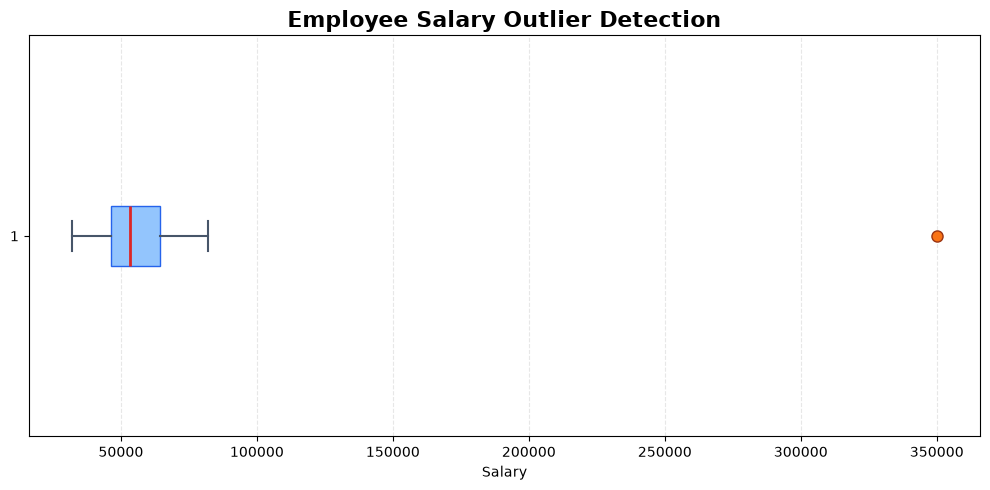

In [4]:
plt.figure(figsize=(10, 5))

plt.boxplot(
    df["Salary"],
    vert=False,
    patch_artist=True,
    boxprops={"facecolor": "#93C5FD", "color": "#2563EB"},
    medianprops={"color": "#DC2626", "linewidth": 2},
    whiskerprops={"color": "#475569", "linewidth": 1.5},
    capprops={"color": "#475569", "linewidth": 1.5},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#F97316",
        "markeredgecolor": "#9A3412",
        "markersize": 8
    }
)

plt.title(
    "Employee Salary Outlier Detection",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Salary")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "salary_boxplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df["Salary"] < lower_bound) |
    (df["Salary"] > upper_bound)
]

print(f"Q1: {Q1:.2f}")
print(f"Q3: {Q3:.2f}")
print(f"IQR: {IQR:.2f}")
print(f"Lower Bound: {lower_bound:.2f}")
print(f"Upper Bound: {upper_bound:.2f}")

print("\nPotential Outliers:")
display(outliers if not outliers.empty else pd.DataFrame(columns=df.columns))

print("Number of potential outliers:", len(outliers))

Q1: 46250.00
Q3: 64250.00
IQR: 18000.00
Lower Bound: 19250.00
Upper Bound: 91250.00

Potential Outliers:


,Employee_ID,Department,Salary
29,130,IT,350000


Number of potential outliers: 1


In [6]:
print("OUTLIER DETECTION REPORT")
print("-" * 35)

print("Total records:", len(df))
print("Potential outliers:", len(outliers))
print("Minimum salary:", df["Salary"].min())
print("Maximum salary:", df["Salary"].max())

if outliers.empty:
    print("\nNo potential outliers were detected using the 1.5 × IQR rule.")
else:
    print("\nPotential outlier records:")
    for _, row in outliers.iterrows():
        print(
            f"Employee ID: {row['Employee_ID']}, "
            f"Department: {row['Department']}, "
            f"Salary: {row['Salary']:,}"
        )

print("\nInterpretation:")
print(
    "Values outside the IQR bounds require investigation. "
    "They should not be removed without understanding their cause."
)

OUTLIER DETECTION REPORT
-----------------------------------
Total records: 30
Potential outliers: 1
Minimum salary: 32000
Maximum salary: 350000

Potential outlier records:
Employee ID: 130, Department: IT, Salary: 350,000

Interpretation:
Values outside the IQR bounds require investigation. They should not be removed without understanding their cause.


C:\Users\HELLO\AppData\Local\Temp\ipykernel_19912\4084292155.py:59: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax1.boxplot(


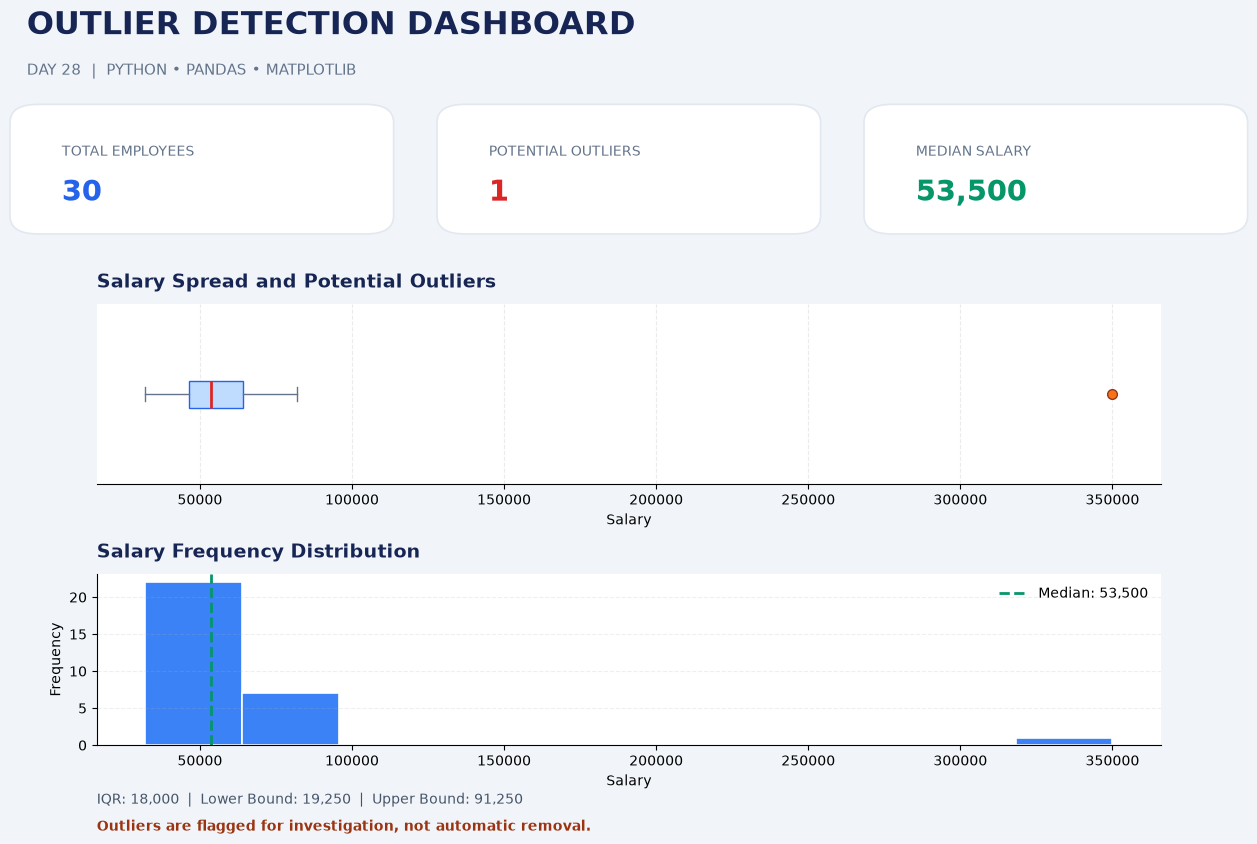

In [7]:
from matplotlib.patches import FancyBboxPatch

salary = df["Salary"]

Q1 = salary.quantile(0.25)
Q3 = salary.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (salary < lower_bound) | (salary > upper_bound)
]

fig = plt.figure(figsize=(14, 9), facecolor="#F1F5F9")

fig.text(
    0.07, 0.93,
    "OUTLIER DETECTION DASHBOARD",
    fontsize=23, fontweight="bold", color="#172554"
)

fig.text(
    0.07, 0.885,
    "DAY 28  |  PYTHON • PANDAS • MATPLOTLIB",
    fontsize=11, color="#64748B"
)

def add_card(x, title, value, color):
    card = FancyBboxPatch(
        (x, 0.72), 0.25, 0.12,
        boxstyle="round,pad=0.012,rounding_size=0.02",
        transform=fig.transFigure,
        facecolor="white",
        edgecolor="#E2E8F0",
        linewidth=1.2
    )
    fig.patches.append(card)

    fig.text(
        x + 0.025, 0.795,
        title, fontsize=10, color="#64748B"
    )

    fig.text(
        x + 0.025, 0.745,
        value, fontsize=21, fontweight="bold", color=color
    )

add_card(0.07, "TOTAL EMPLOYEES", f"{len(df)}", "#2563EB")
add_card(0.375, "POTENTIAL OUTLIERS", f"{len(outliers)}", "#DC2626")
add_card(0.68, "MEDIAN SALARY", f"{salary.median():,.0f}", "#059669")

# Box plot
ax1 = fig.add_axes([0.12, 0.43, 0.76, 0.20])
ax1.set_facecolor("white")

ax1.boxplot(
    salary,
    vert=False,
    patch_artist=True,
    boxprops={"facecolor": "#BFDBFE", "color": "#2563EB"},
    medianprops={"color": "#DC2626", "linewidth": 2},
    whiskerprops={"color": "#64748B"},
    capprops={"color": "#64748B"},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#F97316",
        "markeredgecolor": "#9A3412",
        "markersize": 7
    }
)

ax1.set_title(
    "Salary Spread and Potential Outliers",
    loc="left", fontsize=14, fontweight="bold",
    color="#172554", pad=12
)
ax1.set_xlabel("Salary")
ax1.set_yticks([])
ax1.grid(axis="x", linestyle="--", alpha=0.25)
ax1.spines[["top", "right", "left"]].set_visible(False)

# Salary distribution histogram
ax2 = fig.add_axes([0.12, 0.14, 0.76, 0.19])
ax2.set_facecolor("white")

ax2.hist(
    salary,
    bins=10,
    color="#3B82F6",
    edgecolor="white",
    linewidth=1.2
)

ax2.axvline(
    salary.median(),
    color="#059669",
    linestyle="--",
    linewidth=2,
    label=f"Median: {salary.median():,.0f}"
)

ax2.set_title(
    "Salary Frequency Distribution",
    loc="left", fontsize=14, fontweight="bold",
    color="#172554", pad=12
)
ax2.set_xlabel("Salary")
ax2.set_ylabel("Frequency")
ax2.legend(frameon=False)
ax2.grid(axis="y", linestyle="--", alpha=0.2)
ax2.spines[["top", "right"]].set_visible(False)

fig.text(
    0.12, 0.075,
    f"IQR: {IQR:,.0f}  |  Lower Bound: {lower_bound:,.0f}"
    f"  |  Upper Bound: {upper_bound:,.0f}",
    fontsize=10, color="#475569"
)

fig.text(
    0.12, 0.045,
    "Outliers are flagged for investigation, not automatic removal.",
    fontsize=10, fontweight="bold", color="#9A3412"
)

plt.savefig(
    "outlier_detection_dashboard.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

In [8]:
outliers.to_csv("potential_outliers.csv", index=False)

print("Potential outlier records saved to potential_outliers.csv")

Potential outlier records saved to potential_outliers.csv
